# Tianeptine – OGD bulk RNA-seq: Pathway analysis

**Data:** Differential expression results from notebook 02.

**Aim:** Identify biological processes and pathways affected by OGD and by tianeptine, using over-representation analysis (ORA) with g:Profiler and gene set enrichment analysis (GSEA) with gseapy.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gseapy as gp
import seaborn as sns

from gprofiler import GProfiler

## 1. Load differential expression results

In [2]:
res_ogd = pd.read_csv("../results/DE_OGD_vs_CTRL_vehicle.csv", index_col=0)
res_ogd.shape

(18665, 6)

## 2. Over-representation analysis (ORA): OGD effect in vehicle

Genes significantly changed by OGD (padj ≤ 0.05, |log2FC| ≥ 1) are tested for enrichment against all tested genes as background.

In [3]:
background = res_ogd.index.tolist()
len(background)

18665

In [4]:
sig_ogd = res_ogd[(res_ogd["padj"] <= 0.05) & (res_ogd["log2FoldChange"].abs() >= 1)]
genes_ogd = sig_ogd.index.tolist()
len(genes_ogd)

1832

### 2.1 All OGD-regulated genes

In [5]:
gp_prof = GProfiler(return_dataframe=True)

In [6]:
ora_ogd = gp_prof.profile(
    organism="mmusculus",
    query=genes_ogd,
    sources=["GO:BP", "KEGG"],
    background=background,
    domain_scope="custom_annotated",
    significance_threshold_method="g_SCS",
    user_threshold=0.05,
)
ora_ogd.shape

(202, 14)

In [7]:
ora_ogd["source"].value_counts()

source
GO:BP    176
KEGG      26
Name: count, dtype: int64

In [8]:
ora_ogd[ora_ogd["source"] == "KEGG"][["name", "p_value", "intersection_size", "term_size"]]

,name,p_value,intersection_size,term_size
2,Neuroactive ligand-receptor interaction,3.376520e-23,79,227
27,Calcium signaling pathway,2.153729e-10,55,206
37,Neuroactive ligand signaling,1.565272e-08,44,161
82,KEGG root term,1.473155e-05,709,6303
84,Cytokine-cytokine receptor interaction,1.805344e-05,31,117
102,Hormone signaling,1.618121e-04,35,154
103,ECM-receptor interaction,1.805813e-04,22,75
111,Protein digestion and absorption,5.146807e-04,20,68
115,Integrin signaling,6.544181e-04,30,130
127,Hematopoietic cell lineage,1.125169e-03,15,44


In [9]:
ora_ogd = ora_ogd[~ora_ogd["native"].isin(["KEGG:00000", "GO:0008150"])]
ora_ogd.shape

(200, 14)

In [10]:
ora_ogd[ora_ogd["source"] == "GO:BP"][["name", "p_value", "intersection_size", "term_size"]].head(20)

,name,p_value,intersection_size,term_size
0,cell communication,1.344532e-25,600,4151
1,signaling,2.760014e-24,591,4113
3,multicellular organismal process,1.446772e-21,657,4815
4,signal transduction,9.639783e-20,532,3737
5,response to stimulus,1.255716e-18,745,5768
6,regulation of multicellular organismal process,1.729477e-17,330,2063
7,cell adhesion,1.786577e-16,193,1011
8,anatomical structure development,1.848546e-15,578,4321
9,response to chemical,6.173858e-15,362,2409
10,developmental process,1.855111e-14,610,4663


In [11]:
ora_ogd[(ora_ogd["source"] == "GO:BP") & (ora_ogd["term_size"] <= 500)][["name", "p_value", "intersection_size", "term_size"]].head(20)

,name,p_value,intersection_size,term_size
31,response to wounding,2.996847e-09,86,383
32,blood vessel morphogenesis,5.404813e-09,100,482
35,positive regulation of locomotion,7.956944e-09,87,396
41,positive regulation of cell migration,2.453851e-08,82,370
44,cell-substrate adhesion,4.478461e-08,66,270
47,positive regulation of cell motility,6.309897e-08,83,383
50,inflammatory response,1.265765e-07,96,478
56,wound healing,4.822216e-07,62,258
59,positive regulation of cell adhesion,7.393971e-07,71,319
62,angiogenesis,1.186006e-06,83,404


#### Interpretation

**Settings:** g:Profiler, *Mus musculus*, GO:BP + KEGG, custom background (18,665 tested genes, `custom_annotated`), g:SCS correction, threshold 0.05. Root terms (`KEGG:00000`, `GO:0008150`) were removed.

**Result:** 175 GO:BP terms and 25 KEGG pathways were significantly enriched.

**Comparison with the published analysis (Fig. 4E):**
The original study used g:Profiler (version e94_eg41_p11) with Bonferroni correction and reported 16 KEGG pathways.
- **12 of 16** pathways were reproduced with very similar gene counts (e.g. neuroactive ligand-receptor interaction 75 → 79, calcium signaling 45 → 55, p53 signaling 18 → 18).
- The 4 pathways not reproduced (gap junction, nicotine addiction, ovarian steroidogenesis, morphine addiction) were among the weakest in the original analysis. They are likely sensitive to differences in the DEG list (1675 vs 1832 genes), the correction method and the KEGG database version.
- Several additional pathways (e.g. neuroactive ligand signaling, hormone signaling, integrin signaling, cadherin signaling) are recent additions to KEGG and did not exist in the database version used originally.

**GO:BP terms:** The top-ranked terms by p-value were very broad (e.g. "cell communication", "signaling"; >4,000 genes each). Filtering the display to terms with ≤ 500 genes revealed four main themes:
1. **Wound / injury response and inflammation** (response to wounding, inflammatory response, regulation of defense response), consistent with TNF, NF-κB and cytokine pathways in KEGG.
2. **Angiogenesis and vasculature development**, likely reflecting hypoxia-induced genes rather than actual vessel formation.
3. **Cell migration and adhesion**, consistent with ECM-receptor interaction and integrin/cadherin signaling in KEGG.
4. **G protein-coupled receptor / cAMP signaling**, consistent with neuroactive ligand-receptor interaction and cAMP signaling in KEGG.

**Limitation:** Up- and downregulated genes were analysed together, so the direction of change for each term is not known. This is addressed in the next section.

### 2.2 Up- and downregulated genes separately

In [12]:
genes_up = sig_ogd[sig_ogd["log2FoldChange"] > 0].index.tolist()
genes_down = sig_ogd[sig_ogd["log2FoldChange"] < 0].index.tolist()
len(genes_up), len(genes_down)

(934, 898)

In [13]:
ora_updown = gp_prof.profile(
    organism="mmusculus",
    query={"up": genes_up, "down": genes_down},
    sources=["GO:BP", "KEGG"],
    background=background,
    domain_scope="custom_annotated",
    significance_threshold_method="g_SCS",
    user_threshold=0.05,
)
ora_updown = ora_updown[~ora_updown["native"].isin(["KEGG:00000", "GO:0008150"])]
ora_updown.groupby("query")["source"].value_counts()

query  source
down   GO:BP      42
       KEGG       10
up     GO:BP     263
       KEGG       43
Name: count, dtype: int64

#### 2.2.1 KEGG pathways

##### Upregulated genes

In [14]:
ora_updown[(ora_updown["query"] == "up") & (ora_updown["source"] == "KEGG")][["name", "p_value", "intersection_size", "term_size"]]

,name,p_value,intersection_size,term_size
112,Pathways in cancer,9.268916e-09,57,451
131,Cytokine-cytokine receptor interaction,2.988248e-07,24,117
134,NF-kappa B signaling pathway,3.369391e-07,20,83
162,TNF signaling pathway,3.316325e-06,20,94
167,Proteoglycans in cancer,8.842882e-06,28,180
169,p53 signaling pathway,1.109589e-05,17,74
172,ECM-receptor interaction,1.369291e-05,17,75
177,PI3K-Akt signaling pathway,1.918366e-05,37,292
185,Fluid shear stress and atherosclerosis,5.119546e-05,21,120
189,Cell cycle,6.408664e-05,24,153


##### Downregulated genes

In [15]:
ora_updown[(ora_updown["query"] == "down") & (ora_updown["source"] == "KEGG")][["name", "p_value", "intersection_size", "term_size"]]

,name,p_value,intersection_size,term_size
3,Neuroactive ligand-receptor interaction,1.004886e-25,59,227
51,Calcium signaling pathway,1.228488e-14,43,206
64,Neuroactive ligand signaling,4.127781e-13,36,161
179,Hormone signaling,2.939315e-05,24,154
214,cAMP signaling pathway,3.130800e-04,24,175
221,Nicotine addiction,5.254274e-04,10,36
298,Morphine addiction,1.074293e-02,13,80
322,Taste transduction,2.167733e-02,9,44
347,Protein digestion and absorption,3.851449e-02,11,68
350,Serotonergic synapse,4.056263e-02,13,91


##### Interpretation

Up- and downregulated genes were analysed as two separate queries in a single g:Profiler call, using the same settings and background as above.

| Query | Genes | GO:BP terms | KEGG pathways |
|---|---|---|---|
| Up | 934 | 263 | 43 |
| Down | 898 | 42 | 10 |

Although the two gene lists are of similar size, upregulated genes were enriched in many more terms. This suggests that genes induced by OGD belong to coherent biological programmes, whereas downregulated genes are concentrated in a smaller number of processes.

**Upregulated genes (43 KEGG pathways)**: OGD activates injury and stress responses:
- **Inflammation / innate immunity:** cytokine-cytokine receptor interaction, NF-κB, TNF, Toll-like receptor and IL-17 signaling, complement, efferocytosis
- **Cell death and stress:** p53 signaling, apoptosis, cellular senescence, ferroptosis, cell cycle (consistent with increased *Trp53* by qPCR)
- **Oxidative stress:** glutathione metabolism, metabolism of xenobiotics by cytochrome P450
- **Extracellular matrix and cytoskeleton:** ECM-receptor interaction, integrin signaling, regulation of actin cytoskeleton
- **Survival / growth signaling:** PI3K-Akt, MAPK, Hippo

Many disease-named pathways (e.g. "Pathways in cancer", "Influenza A", "Hepatitis B", "Rheumatoid arthritis") reuse the same signaling genes (NF-κB, TNF, p53, cytokines, MAPK). They reflect the inflammatory and stress response, not the diseases themselves.

**Downregulated genes (10 KEGG pathways)**: OGD suppresses neuronal signaling:
- **Receptors and neurotransmission:** neuroactive ligand-receptor interaction, neuroactive ligand signaling, serotonergic synapse
- **Second messengers:** calcium signaling, cAMP signaling
- **Other:** hormone signaling, nicotine addiction, morphine addiction, taste transduction, protein digestion and absorption

"Nicotine addiction", "morphine addiction" and "taste transduction" are driven by shared receptor, ion channel and G protein genes (e.g. nicotinic acetylcholine, GABA and opioid receptors), not by addiction or taste biology.

**Key observations**
- The two strongest pathways of the combined analysis (neuroactive ligand-receptor interaction and calcium signaling) come entirely from **downregulated** genes. They were even more significant when analysed separately (p = 1.0e-25 and 1.2e-14).
- Two published pathways that were lost in the combined analysis (**nicotine addiction** and **morphine addiction**) were recovered in the downregulated set. With this, **14 of the 16** published KEGG pathways are reproduced. Only gap junction and ovarian steroidogenesis were not detected.
- Overall, OGD induces inflammation, cell death and oxidative stress programmes while suppressing neuronal receptor and synaptic signaling, a pattern typical of ischaemic injury.
- Tianeptine is known to act on the μ-opioid receptor. The downregulation of opioid- and serotonin-related pathways by OGD is therefore relevant, but this analysis reflects the OGD effect in vehicle only. Whether tianeptine modifies these pathways is tested in the tianeptine comparisons.

#### 2.2.2 GO Biological Process terms

##### Upregulated genes

In [16]:
ora_updown[(ora_updown["query"] == "up") & (ora_updown["source"] == "GO:BP") & (ora_updown["term_size"] <= 500)][["name", "p_value", "intersection_size", "term_size"]].head(25)

,name,p_value,intersection_size,term_size
39,inflammatory response,1.264362e-15,77,478
43,response to wounding,4.622083e-15,67,383
56,regulation of defense response,5.107426e-14,76,497
57,positive regulation of cell migration,5.778107e-14,64,370
58,positive regulation of cell motility,8.462145e-14,65,383
59,positive regulation of locomotion,1.206167e-13,66,396
66,blood vessel morphogenesis,4.426678e-13,73,482
78,wound healing,3.204067e-12,50,258
95,response to bacterium,6.538778e-11,59,370
99,positive regulation of response to external st...,1.104803e-10,62,407


##### Downregulated genes

In [17]:
ora_updown[(ora_updown["query"] == "down") & (ora_updown["source"] == "GO:BP") & (ora_updown["term_size"] <= 500)][["name", "p_value", "intersection_size", "term_size"]].head(25)

,name,p_value,intersection_size,term_size
142,potassium ion transport,6.886171e-07,32,169
146,adenylate cyclase-modulating G protein-coupled...,9.419487e-07,28,133
160,regulation of membrane potential,2.802518e-06,47,345
165,calcium ion transport,7.164319e-06,41,283
182,potassium ion transmembrane transport,4.019182e-05,27,145
198,sensory perception of pain,1.279983e-04,18,70
201,regulation of postsynaptic membrane potential,1.706929e-04,23,115
211,modulation of chemical synaptic transmission,2.569480e-04,49,421
212,regulation of trans-synaptic signaling,2.778786e-04,49,422
226,calcium ion transmembrane transport,8.117634e-04,31,210


##### Interpretation

GO:BP terms were filtered to ≤ 500 genes for display, as in section 2.1.

**Upregulated genes**: the same themes as in the combined analysis (2.1), but with much stronger p-values (e.g. inflammatory response: 1.3e-07 combined vs 1.3e-15 upregulated only), confirming that these themes are driven by upregulated genes:
- **Inflammation and injury response:** inflammatory response, response to wounding, wound healing, regulation of defense response, cytokine production, response to type II interferon
- **Cell death:** apoptotic signaling pathway
- **Angiogenesis / vasculature development:** likely reflecting hypoxia-induced genes
- **Cell migration and adhesion:** positive regulation of cell migration, motility and adhesion; cell-substrate adhesion

Terms such as "response to bacterium" are driven by shared inflammatory genes and do not indicate infection. Terms named "negative regulation of ..." describe genes that inhibit a process. In this table these inhibitory genes are *increased*, which does not mean that the process itself is reduced.

**Downregulated genes**: consistent with the KEGG results (2.2.1), OGD suppresses neuronal electrical and synaptic function:
- **Ion transport and membrane potential:** potassium and calcium ion transport, regulation of (postsynaptic) membrane potential
- **Synaptic transmission:** chemical and glutamatergic synaptic transmission, trans-synaptic signaling, glutamate receptor signaling
- **Neurotransmitter release:** neurotransmitter transport and secretion, regulated exocytosis
- **G protein-coupled receptor / cAMP signaling:** adenylate cyclase-modulating GPCR signaling

Terms such as "sensory perception of pain" and "cognition" are driven by shared receptor and ion channel genes and should not be interpreted literally in a cell culture model.

The downregulation of glutamate receptor signaling may reflect an adaptive response to excitotoxicity, but its functional consequence cannot be determined from transcript levels alone.

**Summary of section 2:** OGD induces inflammation, cell death and oxidative stress programmes while suppressing neuronal ion channel, receptor and synaptic signaling genes.

## 3. Over-representation analysis (ORA): OGD effect in tianeptine

Genes significantly changed by OGD in tianeptine-treated cultures (OGD-TIA vs CONTROL-TIA; padj ≤ 0.05, |log2FC| ≥ 1) are tested with the same settings as in section 2.

In [18]:
res_ogd_tia = pd.read_csv("../results/DE_OGD_vs_CTRL_tianeptine.csv", index_col=0)
res_ogd_tia.shape

(18665, 6)

In [19]:
res_ogd_tia.index.equals(res_ogd.index)

True

In [20]:
sig_ogd_tia = res_ogd_tia[(res_ogd_tia["padj"] <= 0.05) & (res_ogd_tia["log2FoldChange"].abs() >= 1)]
genes_ogd_tia = sig_ogd_tia.index.tolist()
len(genes_ogd_tia)

292

### 3.1 All OGD-regulated genes

In [21]:
ora_ogd_tia = gp_prof.profile(
    organism="mmusculus",
    query=genes_ogd_tia,
    sources=["GO:BP", "KEGG"],
    background=background,
    domain_scope="custom_annotated",
    significance_threshold_method="g_SCS",
    user_threshold=0.05,
)
ora_ogd_tia = ora_ogd_tia[~ora_ogd_tia["native"].isin(["KEGG:00000", "GO:0008150"])]
ora_ogd_tia["source"].value_counts()

source
GO:BP    28
KEGG      5
Name: count, dtype: int64

#### 3.1.1 KEGG pathways

In [22]:
ora_ogd_tia[ora_ogd_tia["source"] == "KEGG"][["name", "p_value", "intersection_size", "term_size"]]

,name,p_value,intersection_size,term_size
1,Neuroactive ligand-receptor interaction,0.000043,16,227
7,Viral protein interaction with cytokine and cy...,0.000517,6,30
12,Cytokine-cytokine receptor interaction,0.001218,10,117
23,Cytoskeleton in muscle cells,0.011838,11,183
24,ECM-receptor interaction,0.014470,7,75


#### 3.1.2 GO Biological Process terms

In [23]:
ora_ogd_tia[ora_ogd_tia["source"] == "GO:BP"][["name", "p_value", "intersection_size", "term_size"]]

,name,p_value,intersection_size,term_size
0,cell communication,0.000018,109,4151
2,signal transduction,0.000057,100,3737
3,signaling,0.000115,106,4113
4,multicellular organismal process,0.000164,118,4815
5,cellular response to chemical stimulus,0.000168,53,1478
6,developmental process,0.000212,115,4663
8,response to stimulus,0.000819,132,5768
9,wound healing,0.000851,19,258
10,anatomical structure development,0.000917,107,4321
11,response to chemical,0.000936,71,2409


#### Interpretation

**Result:** 28 GO:BP terms and 5 KEGG pathways were significantly enriched among the 292 OGD-regulated genes in tianeptine-treated cultures (vehicle: 175 GO:BP terms and 25 KEGG pathways from 1832 genes).

**Comparison with the published analysis (Fig. 4E):** The original study reported 2 KEGG pathways for OGD-TIA vs CONTROL-TIA.
- **Neuroactive ligand-receptor interaction** was reproduced and is again the top pathway (16 genes; published: 22).
- **TNF signaling pathway** was not significant. However, the inflammatory signal is still present through two closely related pathways that share many cytokine genes: cytokine-cytokine receptor interaction and viral protein interaction with cytokine and cytokine receptor.

**KEGG pathways:** neuroactive ligand-receptor interaction, viral protein interaction with cytokine and cytokine receptor, cytokine-cytokine receptor interaction, cytoskeleton in muscle cells, ECM-receptor interaction. All five were also enriched in the vehicle analysis (section 2).

**GO:BP terms:** most terms are very broad (> 1,000 genes). The more specific terms (≤ 500 genes) reflect the same themes as in vehicle:
- **Injury response and inflammation:** wound healing, response to wounding, inflammatory response
- **G protein-coupled receptor / cAMP signaling:** adenylate cyclase-activating and -modulating GPCR signaling
- **Cell migration:** positive regulation of locomotion
- **Growth factor response:** response to fibroblast growth factor

**Note:** No new pathways or themes appeared in tianeptine-treated cultures; the OGD response contains fewer enriched terms. This should not be interpreted as tianeptine reducing these pathways. With 292 instead of 1832 genes, the analysis has much lower statistical power, so absence of enrichment is not evidence of absence. This is discussed further in section 3.3.

### 3.2 Up- and downregulated genes separately

In [24]:
genes_up_tia = sig_ogd_tia[sig_ogd_tia["log2FoldChange"] > 0].index.tolist()
genes_down_tia = sig_ogd_tia[sig_ogd_tia["log2FoldChange"] < 0].index.tolist()
len(genes_up_tia), len(genes_down_tia)

(151, 141)

In [25]:
ora_updown_tia = gp_prof.profile(
    organism="mmusculus",
    query={"up": genes_up_tia, "down": genes_down_tia},
    sources=["GO:BP", "KEGG"],
    background=background,
    domain_scope="custom_annotated",
    significance_threshold_method="g_SCS",
    user_threshold=0.05,
)
ora_updown_tia = ora_updown_tia[~ora_updown_tia["native"].isin(["KEGG:00000", "GO:0008150"])]
ora_updown_tia.groupby("query")["source"].value_counts()

query  source
down   KEGG       4
       GO:BP      2
up     GO:BP     56
       KEGG       8
Name: count, dtype: int64

#### 3.2.1 KEGG pathways

##### Upregulated genes

In [26]:
ora_updown_tia[(ora_updown_tia["query"] == "up") & (ora_updown_tia["source"] == "KEGG")][["name", "p_value", "intersection_size", "term_size"]]

,name,p_value,intersection_size,term_size
8,Cytokine-cytokine receptor interaction,0.000038,9,117
23,Viral protein interaction with cytokine and cy...,0.000327,5,30
30,TNF signaling pathway,0.000927,7,94
46,IL-17 signaling pathway,0.010315,5,60
47,Arachidonic acid metabolism,0.010374,4,32
61,Influenza A,0.019470,6,107
64,ECM-receptor interaction,0.029590,5,75
70,NOD-like receptor signaling pathway,0.048826,6,127


##### Downregulated genes

In [27]:
ora_updown_tia[(ora_updown_tia["query"] == "down") & (ora_updown_tia["source"] == "KEGG")][["name", "p_value", "intersection_size", "term_size"]]

,name,p_value,intersection_size,term_size
2,Neuroactive ligand-receptor interaction,0.000008,12,227
49,Hormone signaling,0.010602,7,154
52,Neuroactive ligand signaling,0.013971,7,161
65,Circadian entrainment,0.031414,5,85


##### Interpretation

| Query | Genes | GO:BP terms | KEGG pathways |
|---|---|---|---|
| Up | 151 | 56 | 8 |
| Down | 141 | 2 | 4 |

As in vehicle, upregulated genes were enriched in many more terms than downregulated genes.

**Upregulated genes (8 KEGG pathways)**: mainly **inflammation**: cytokine-cytokine receptor interaction, viral protein interaction with cytokine and cytokine receptor, TNF signaling, IL-17 signaling, NOD-like receptor signaling, arachidonic acid metabolism (inflammatory lipid mediators), Influenza A (driven by shared inflammatory genes), and ECM-receptor interaction.

**Downregulated genes (4 KEGG pathways)**: **neuronal receptor signaling**: neuroactive ligand-receptor interaction, neuroactive ligand signaling, hormone signaling, circadian entrainment.

**Key observations**
- **Both published pathways are reproduced** when up- and downregulated genes are analysed separately: neuroactive ligand-receptor interaction (downregulated) and **TNF signaling** (upregulated; 7 genes, published: 10). TNF signaling was not significant in the combined analysis (3.1), similar to nicotine and morphine addiction in vehicle (2.2.1).
- The core OGD response (inflammation up, neuronal receptor signaling down) is present in both vehicle and tianeptine-treated cultures.
- Several pathways enriched in vehicle were **not** detected here, notably cell death and oxidative stress pathways among upregulated genes (p53 signaling, apoptosis, cellular senescence, ferroptosis, glutathione metabolism) and calcium and cAMP signaling among downregulated genes. However, apoptotic signaling is enriched at the GO:BP level in tianeptine (see 3.2.2), so the absence of these KEGG pathways most likely reflects lower power rather than absence of a cell death response.
- Arachidonic acid metabolism, NOD-like receptor signaling and circadian entrainment were detected here but not in vehicle. These are supported by few genes (4–6) and are close to the significance threshold.

**Caution:** These differences are observations, not evidence of a tianeptine effect. The tianeptine gene lists are about six times smaller than in vehicle, so many pathways may fall below the significance threshold because of lower power. A direct test of whether tianeptine modifies the OGD response requires the interaction analysis (notebook 02) or GSEA of the tianeptine comparisons.

#### 3.2.2 GO Biological Process terms

##### Upregulated genes

In [28]:
ora_updown_tia[(ora_updown_tia["query"] == "up") & (ora_updown_tia["source"] == "GO:BP") & (ora_updown_tia["term_size"] <= 500)][["name", "p_value", "intersection_size", "term_size"]].head(25)

,name,p_value,intersection_size,term_size
4,wound healing,0.000015,16,258
12,apoptotic signaling pathway,0.000062,20,469
15,response to wounding,0.000097,18,383
25,positive regulation of cell motility,0.000659,17,383
33,positive regulation of locomotion,0.001077,17,396
37,positive regulation of cell migration,0.002603,16,370
48,morphogenesis of an epithelium,0.010570,16,410
53,inflammatory response,0.016018,17,478
62,tissue morphogenesis,0.023976,17,492
66,intrinsic apoptotic signaling pathway,0.035814,12,245


##### Downregulated genes

In [29]:
ora_updown_tia[(ora_updown_tia["query"] == "down") & (ora_updown_tia["source"] == "GO:BP")][["name", "p_value", "intersection_size", "term_size"]]

,name,p_value,intersection_size,term_size
35,G protein-coupled receptor signaling pathway,0.002361,18,532
55,transmembrane transport,0.016676,24,1042


##### Interpretation

**Upregulated genes** (11 terms with ≤ 500 genes): the same themes as in vehicle (2.2.2):
- **Injury response and inflammation:** wound healing, response to wounding, inflammatory response
- **Cell death:** apoptotic signaling pathway (20 genes, p = 6.2e-05) and intrinsic apoptotic signaling pathway
- **Cell migration:** positive regulation of cell motility, locomotion and cell migration
- **Tissue and vascular development:** morphogenesis of an epithelium, tissue morphogenesis, regulation of angiogenesis

**Downregulated genes** (2 terms): G protein-coupled receptor signaling pathway and transmembrane transport, consistent with the downregulation of neuronal receptor and ion channel genes seen in KEGG (3.2.1) and in vehicle.

**Important:** Apoptotic signaling is one of the strongest terms among upregulated genes, so a cell death response to OGD is present in tianeptine-treated cultures as well. This shows why missing pathways in a smaller gene list should not be interpreted as a tianeptine effect.

**Summary of section 3:** In tianeptine-treated cultures, OGD induces the same core response as in vehicle (inflammation, injury response, apoptotic signaling and cell migration up; neuronal receptor signaling down), but with far fewer differentially expressed genes (292 vs 1832) and fewer enriched terms. Both pathways reported in the original study (neuroactive ligand-receptor interaction and TNF signaling) were reproduced.

### 3.3 Comparison with vehicle

KEGG pathways enriched among OGD-regulated genes are compared between vehicle (section 2.2.1) and tianeptine (section 3.2.1), separately for up- and downregulated genes.

**Note:** This comparison is descriptive. A pathway that is significant in one condition but not in the other is not evidence of a difference between conditions, especially because the tianeptine gene lists are about six times smaller.

In [30]:
def print_list(title, names):
    print(f"{title} ({len(names)}):")
    for name in sorted(names):
        print("  -", name)
    print()

#### 3.3.1 Upregulated genes

In [31]:
kegg_veh_up = set(ora_updown[(ora_updown["query"] == "up") & (ora_updown["source"] == "KEGG")]["name"])
kegg_tia_up = set(ora_updown_tia[(ora_updown_tia["query"] == "up") & (ora_updown_tia["source"] == "KEGG")]["name"])
print_list("Shared", kegg_veh_up & kegg_tia_up)
print_list("Only vehicle", kegg_veh_up - kegg_tia_up)
print_list("Only tianeptine", kegg_tia_up - kegg_veh_up)

Shared (6):
  - Cytokine-cytokine receptor interaction
  - ECM-receptor interaction
  - IL-17 signaling pathway
  - Influenza A
  - TNF signaling pathway
  - Viral protein interaction with cytokine and cytokine receptor

Only vehicle (37):
  - Amoebiasis
  - Apoptosis
  - Breast cancer
  - Cell cycle
  - Cellular senescence
  - Chemical carcinogenesis - DNA adducts
  - Complement and coagulation cascades
  - Cytoskeleton in muscle cells
  - Efferocytosis
  - Epstein-Barr virus infection
  - Ferroptosis
  - Fluid shear stress and atherosclerosis
  - Gastric cancer
  - Glutathione metabolism
  - Hematopoietic cell lineage
  - Hepatitis B
  - Hepatocellular carcinoma
  - Hippo signaling pathway - multiple species
  - Human T-cell leukemia virus 1 infection
  - Human cytomegalovirus infection
  - Human papillomavirus infection
  - Integrin signaling
  - Kaposi sarcoma-associated herpesvirus infection
  - Lipid and atherosclerosis
  - MAPK signaling pathway
  - Metabolism of xenobiotics by 

#### 3.3.2 Downregulated genes

In [32]:
kegg_veh_down = set(ora_updown[(ora_updown["query"] == "down") & (ora_updown["source"] == "KEGG")]["name"])
kegg_tia_down = set(ora_updown_tia[(ora_updown_tia["query"] == "down") & (ora_updown_tia["source"] == "KEGG")]["name"])
print_list("Shared", kegg_veh_down & kegg_tia_down)
print_list("Only vehicle", kegg_veh_down - kegg_tia_down)
print_list("Only tianeptine", kegg_tia_down - kegg_veh_down)

Shared (3):
  - Hormone signaling
  - Neuroactive ligand signaling
  - Neuroactive ligand-receptor interaction

Only vehicle (7):
  - Calcium signaling pathway
  - Morphine addiction
  - Nicotine addiction
  - Protein digestion and absorption
  - Serotonergic synapse
  - Taste transduction
  - cAMP signaling pathway

Only tianeptine (1):
  - Circadian entrainment



#### Interpretation

| | Shared | Only vehicle | Only tianeptine |
|---|---|---|---|
| Upregulated | 6 | 37 | 2 |
| Downregulated | 3 | 7 | 1 |

**Core OGD response shared by both conditions**
- **Upregulated, inflammation:** cytokine-cytokine receptor interaction, TNF signaling, IL-17 signaling, viral protein interaction with cytokine and cytokine receptor, Influenza A, ECM-receptor interaction
- **Downregulated, neuronal receptor signaling:** neuroactive ligand-receptor interaction, neuroactive ligand signaling, hormone signaling

**Detected only in vehicle**
- **Upregulated:** cell death and stress (p53 signaling, apoptosis, cellular senescence, ferroptosis, cell cycle), oxidative stress (glutathione metabolism, metabolism of xenobiotics by cytochrome P450), further inflammatory pathways (NF-κB, Toll-like receptor, complement, efferocytosis), survival signaling (MAPK, PI3K-Akt, Hippo), cytoskeleton and adhesion (integrin signaling, regulation of actin cytoskeleton), and many disease-named pathways driven by the same genes
- **Downregulated:** calcium and cAMP signaling, morphine addiction, nicotine addiction, serotonergic synapse, taste transduction, protein digestion and absorption

**Detected only in tianeptine:** arachidonic acid metabolism and NOD-like receptor signaling (upregulated), circadian entrainment (downregulated). All are supported by few genes and close to the significance threshold.

**Interpretation and limitations**
- Both conditions share the same core OGD response: induction of inflammation and suppression of neuronal receptor signaling.
- In vehicle, this core is accompanied by a much broader response. In tianeptine-treated cultures, many of these pathways are not detected at the KEGG level.
- - The smaller number of OGD-regulated genes in tianeptine (292 vs 1832) is compatible with tianeptine attenuating the OGD response. DESeq2 estimates one dispersion value per gene from all 16 samples, so both comparisons use the same variability estimates. The difference in DEG numbers therefore mainly reflects smaller OGD effect sizes (log2 fold changes) in tianeptine-treated cultures. Atypical samples were present in both OGD groups (X9 in OGD-VEH, X16 in OGD-TIA), and if anything they make the two conditions more similar. Whether the attenuation is statistically significant requires the interaction test (notebook 02: no single gene significant) or pathway-level testing (section 4).
- Even if tianeptine attenuates the OGD response overall, this does not show that specific pathways (e.g. calcium signaling) are affected more than others. Pathways may fall below the significance threshold simply because of the global reduction or lower power. Apoptotic signaling, for example, is still enriched at the GO:BP level in tianeptine (3.2.2).
- The OGD-induced downregulation of calcium signaling and of opioid- and serotonin-related pathways (morphine addiction, serotonergic synapse) was detected only in vehicle. Given that tianeptine acts on the μ-opioid receptor, these are interesting hypotheses that require a direct test.
- A direct test of whether tianeptine modifies the OGD response at the pathway level is performed in section 4 (GSEA).

## 4. Gene set enrichment analysis (GSEA)

ORA only uses genes that pass a significance threshold. GSEA instead ranks **all** tested genes (here by the DESeq2 Wald statistic `stat`, which combines direction and reliability of the change) and tests whether the genes of a gene set are concentrated at the top (positive NES, set increased) or at the bottom (negative NES, set decreased) of the ranking. This allows detection of small but coordinated changes across a pathway, even when no single gene is significant. This is essential for the interaction test, where no individual gene reached significance (notebook 02).

**Comparisons**
- 4.2 OGD-VEH vs CONTROL-VEH: OGD effect in vehicle
- 4.3 OGD-TIA vs CONTROL-TIA: OGD effect in tianeptine
- 4.4 OGD-TIA vs OGD-VEH: tianeptine effect under OGD
- 4.5 Interaction: does tianeptine modify the OGD effect?

### 4.1 Gene sets: MSigDB mouse Hallmark

Mouse-specific gene sets from MSigDB are used. The Hallmark collection contains 50 well-defined biological processes curated to reduce redundancy between sets.

In [33]:
msig = gp.Msigdb()
msig.list_category(dbver="2026.2.Mm")

['m1.all',
 'm2.all',
 'm2.cgp',
 'm2.cp.biocarta',
 'm2.cp.reactome',
 'm2.cp',
 'm2.cp.wikipathways',
 'm3.all',
 'm3.gtrd',
 'm3.mirdb',
 'm5.all',
 'm5.go.bp',
 'm5.go.cc',
 'm5.go.mf',
 'm5.go',
 'm5.mpo.mp',
 'm5.mpo.mpt',
 'm5.mpo',
 'm7.all',
 'm8.all',
 'mh.all',
 'msigdb']

In [34]:
hallmark = msig.get_gmt(category="mh.all", dbver="2026.2.Mm")
len(hallmark)

50

### 4.2 OGD effect in vehicle (OGD-VEH vs CONTROL-VEH)

All 18,665 tested genes are ranked by the DESeq2 Wald statistic (`stat`) from the OGD-VEH vs CONTROL-VEH comparison. Positive values indicate genes increased by OGD, negative values genes decreased by OGD.

In [35]:
rnk_ogd = res_ogd["stat"].dropna().sort_values(ascending=False)
rnk_ogd.head(), rnk_ogd.tail()

(Gene Symbol
 Emp1       10.986234
 Gbp2        9.698695
 Dnttip2     9.312555
 Med22       8.521180
 Ifi30       8.468011
 Name: stat, dtype: float64,
 Gene Symbol
 Dnah5     -7.454780
 Gpr21     -7.814535
 Pcdhga2   -8.610273
 Lrrc7     -9.209244
 Slc30a3   -9.724282
 Name: stat, dtype: float64)

In [36]:
gsea_ogd = gp.prerank(
    rnk=rnk_ogd,
    gene_sets=hallmark,
    min_size=15,
    max_size=500,
    permutation_num=1000,
    seed=42,
    threads=4,
    outdir=None,
)
gsea_ogd.res2d.head(10)

2026-11-20 00:13:30,041 [WARNING] Duplicated values found in preranked stats: 0.04% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,HALLMARK_MYC_TARGETS_V1,0.595097,3.005058,0.0,0.0,0.0,119/187,25.13%,Cnbp;Rsl1d1;Hnrnpc;Rps6;Pcbp1;Hspe1;Pa2g4;Odc1...
1,prerank,HALLMARK_G2M_CHECKPOINT,0.575691,2.933871,0.0,0.0,0.0,128/187,26.18%,Ythdc1;Dbf4;Odc1;Dkc1;G3bp1;Cdk4;Myc;Ss18;Mnat...
2,prerank,HALLMARK_E2F_TARGETS,0.568722,2.907923,0.0,0.0,0.0,141/195,29.42%,Trp53;Pa2g4;Ppm1d;Cdk4;Ranbp1;Myc;Cdkn1a;Eed;C...
3,prerank,HALLMARK_MYC_TARGETS_V2,0.662031,2.764125,0.0,0.0,0.0,39/57,24.24%,Ppan;Hspe1;Mybbp1a;Pa2g4;Imp4;Ddx18;Gnl3;Cdk4;...
4,prerank,HALLMARK_P53_PATHWAY,0.526131,2.664200,0.0,0.0,0.0,94/188,18.29%,Dnttip2;Ifi30;Trp53;Epha2;Pidd1;Hbegf;Atf3;Phl...
5,prerank,HALLMARK_TNFA_SIGNALING_VIA_NFKB,0.522574,2.625717,0.0,0.0,0.0,83/170,18.37%,Cd44;Cxcl10;Clcf1;Fosl1;Hbegf;Dusp4;Csf1;Atf3;...
6,prerank,HALLMARK_IL6_JAK_STAT3_SIGNALING,0.597162,2.560310,0.0,0.0,0.0,23/60,7.08%,Cd44;Cxcl10;Tnfrsf1a;Osmr;Csf1;Fas;Tnfrsf12a;S...
7,prerank,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,0.463168,2.142139,0.0,0.0,0.0,54/104,24.49%,Exosc2;Eif4ebp1;Atf3;Dkc1;Kdelr3;Igfbp1;Eif4a3...
8,prerank,HALLMARK_INTERFERON_GAMMA_RESPONSE,0.440488,2.133102,0.0,0.0,0.0,76/136,30.15%,Ifi30;Tor1b;Cxcl10;Ptgs2;Gbp3;Fas;Mvp;Isg20;St...
9,prerank,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,0.401861,2.024940,0.0,0.0,0.0,78/170,23.84%,Cd44;Timp1;Lgals1;Itga5;Emp3;Vim;Fas;Tnfrsf12a...


In [37]:
gsea_ogd.res2d[["Term", "NES", "NOM p-val", "FDR q-val", "Tag %"]].sort_values("NES", ascending=False)

,Term,NES,NOM p-val,FDR q-val,Tag %
0,HALLMARK_MYC_TARGETS_V1,3.005058,0.000000,0.000000,119/187
1,HALLMARK_G2M_CHECKPOINT,2.933871,0.000000,0.000000,128/187
2,HALLMARK_E2F_TARGETS,2.907923,0.000000,0.000000,141/195
3,HALLMARK_MYC_TARGETS_V2,2.764125,0.000000,0.000000,39/57
4,HALLMARK_P53_PATHWAY,2.664200,0.000000,0.000000,94/188
5,HALLMARK_TNFA_SIGNALING_VIA_NFKB,2.625717,0.000000,0.000000,83/170
6,HALLMARK_IL6_JAK_STAT3_SIGNALING,2.560310,0.000000,0.000000,23/60
7,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,2.142139,0.000000,0.000000,54/104
8,HALLMARK_INTERFERON_GAMMA_RESPONSE,2.133102,0.000000,0.000000,76/136
9,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,2.024940,0.000000,0.000000,78/170


In [38]:
sig_gsea_ogd = gsea_ogd.res2d[gsea_ogd.res2d["FDR q-val"] < 0.05]
(sig_gsea_ogd["NES"] > 0).sum(), (sig_gsea_ogd["NES"] < 0).sum()

(np.int64(26), np.int64(3))

#### Interpretation

**Result:** Of the 50 Hallmark gene sets, 26 were significantly enriched among genes increased by OGD and 3 among genes decreased by OGD (FDR < 0.05). Sets with p = 0 have p < 0.001 (the minimum with 1000 permutations).

**Increased by OGD (positive NES):** the same themes as in ORA (2.2), confirming the ORA results with a threshold-free method:
- **Proliferation / cell cycle:** MYC targets V1 and V2, E2F targets, G2M checkpoint, mitotic spindle. Neurons do not divide, so this signal most likely reflects proliferating glial cells (reactive gliosis) in the culture.
- **Stress and cell death:** p53 pathway, apoptosis, DNA repair, unfolded protein response, reactive oxygen species pathway
- **Inflammation:** TNFα signaling via NF-κB, IL6/JAK/STAT3, interferon α and γ response, inflammatory response, IL2/STAT5, allograft rejection, coagulation
- **Other:** epithelial-mesenchymal transition (e.g. *Cd44*, *Vim*, *Timp1*, markers of reactive glia), xenobiotic metabolism

**Decreased by OGD (negative NES):** KRAS signaling DN, pancreas beta cells, cholesterol homeostasis.

**Limitation of the Hallmark collection:** The strongest ORA finding, downregulation of neuronal receptor and synaptic signaling, has no direct counterpart here because the Hallmark collection contains no neuron- or synapse-specific gene sets. The two strongest decreased sets reflect this indirectly: "pancreas beta cells" contains neuroendocrine genes also expressed in neurons, and "KRAS signaling DN" contains many ion channel and neuronal genes.

**Note:** The Hallmark hypoxia set was only weakly enriched (FDR = 0.10). RNA was collected 6 hours after the end of OGD, under normal oxygen and glucose conditions. The acute HIF-driven hypoxia response is expected to decline quickly after reoxygenation, whereas secondary responses (inflammation, p53/apoptosis, ER and oxidative stress, glial activation) are well developed at this time point. This is consistent with the observed pattern.

### 4.3 OGD effect in tianeptine (OGD-TIA vs CONTROL-TIA)

All tested genes are ranked by the Wald statistic from the OGD-TIA vs CONTROL-TIA comparison and analysed with the same settings as in 4.2.

In [39]:
rnk_ogd_tia = res_ogd_tia["stat"].dropna().sort_values(ascending=False)

gsea_ogd_tia = gp.prerank(
    rnk=rnk_ogd_tia,
    gene_sets=hallmark,
    min_size=15,
    max_size=500,
    permutation_num=1000,
    seed=42,
    threads=4,
    outdir=None,
)
gsea_ogd_tia.res2d[["Term", "NES", "NOM p-val", "FDR q-val", "Tag %"]].sort_values("NES", ascending=False)

2026-11-20 00:13:31,822 [WARNING] Duplicated values found in preranked stats: 0.04% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


,Term,NES,NOM p-val,FDR q-val,Tag %
0,HALLMARK_G2M_CHECKPOINT,2.638429,0.000000,0.000000,95/187
1,HALLMARK_MYC_TARGETS_V1,2.547098,0.000000,0.000000,111/187
2,HALLMARK_E2F_TARGETS,2.526462,0.000000,0.000000,121/195
3,HALLMARK_P53_PATHWAY,2.260003,0.000000,0.000000,92/188
4,HALLMARK_MYC_TARGETS_V2,2.241208,0.000000,0.000000,34/57
5,HALLMARK_IL6_JAK_STAT3_SIGNALING,2.192071,0.000000,0.000000,28/60
6,HALLMARK_DNA_REPAIR,1.898474,0.000000,0.001176,74/144
9,HALLMARK_TNFA_SIGNALING_VIA_NFKB,1.878629,0.000000,0.001544,66/170
10,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,1.841936,0.000000,0.001525,49/104
11,HALLMARK_WNT_BETA_CATENIN_SIGNALING,1.829269,0.000000,0.001510,19/39


In [40]:
sig_gsea_ogd_tia = gsea_ogd_tia.res2d[gsea_ogd_tia.res2d["FDR q-val"] < 0.05]
(sig_gsea_ogd_tia["NES"] > 0).sum(), (sig_gsea_ogd_tia["NES"] < 0).sum()

(np.int64(20), np.int64(5))

#### Interpretation

**Result:** 20 Hallmark gene sets were significantly increased and 5 decreased by OGD in tianeptine-treated cultures (FDR < 0.05; vehicle: 26 and 3).

**Same core response as in vehicle.** Nearly all themes enriched in vehicle (4.2) are also strongly enriched here:
- **Proliferation / cell cycle:** G2M checkpoint, MYC targets V1 and V2, E2F targets, mitotic spindle
- **Stress and cell death:** p53 pathway, DNA repair, unfolded protein response, apoptosis, reactive oxygen species pathway
- **Inflammation:** IL6/JAK/STAT3, TNFα signaling via NF-κB, interferon α and γ response, allograft rejection, inflammatory response
- **Decreased:** cholesterol homeostasis, KRAS signaling DN, pancreas beta cells, apical junction, glycolysis

**Comparison with ORA (section 3):** In the ORA, several of these processes (e.g. p53 signaling, apoptosis, cell cycle) were not detected in tianeptine-treated cultures. GSEA, which does not depend on a significance threshold for single genes, shows that these responses are clearly present. This confirms that the missing ORA pathways largely reflected lower power, not absence of the response.

**Descriptive differences from vehicle:**
- For most increased gene sets, the NES is somewhat smaller in tianeptine (e.g. TNFα via NF-κB 2.63 vs 1.88; EMT 2.02 vs 1.46; p53 pathway 2.66 vs 2.26), compatible with a moderately attenuated OGD response.
- Glycolysis (NES +1.03 in vehicle, not significant; −1.42 in tianeptine, FDR = 0.047) and hypoxia (+1.27 vs −1.29, both not significant) change in opposite directions. Both are borderline.
- Whether any of these differences is statistically significant is tested directly with the interaction analysis (4.5).

### 4.4 Tianeptine effect under OGD (OGD-TIA vs OGD-VEH)

Genes are ranked by the Wald statistic from the OGD-TIA vs OGD-VEH comparison. Positive NES indicates gene sets higher in tianeptine-treated than in vehicle-treated OGD cultures. At the single-gene level, almost no genes differed significantly between these groups (notebook 02), so this analysis tests whether tianeptine causes small but coordinated shifts in whole gene sets.

In [41]:
res_tia = pd.read_csv("../results/DE_TIA_vs_VEH_OGD.csv", index_col=0)
res_tia.index.equals(res_ogd.index)

True

In [42]:
rnk_tia = res_tia["stat"].dropna().sort_values(ascending=False)

gsea_tia = gp.prerank(
    rnk=rnk_tia,
    gene_sets=hallmark,
    min_size=15,
    max_size=500,
    permutation_num=1000,
    seed=42,
    threads=4,
    outdir=None,
)
gsea_tia.res2d[["Term", "NES", "NOM p-val", "FDR q-val", "Tag %"]].sort_values("NES", ascending=False)

2026-11-20 00:13:33,414 [WARNING] Duplicated values found in preranked stats: 0.04% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


,Term,NES,NOM p-val,FDR q-val,Tag %
27,HALLMARK_KRAS_SIGNALING_DN,1.541893,0.005714,0.040498,49/125
35,HALLMARK_APICAL_JUNCTION,1.290684,0.055970,0.186636,46/173
36,HALLMARK_PANCREAS_BETA_CELLS,1.258278,0.166667,0.157854,12/28
44,HALLMARK_HEDGEHOG_SIGNALING,1.026411,0.423006,0.493572,14/34
47,HALLMARK_SPERMATOGENESIS,0.955603,0.539216,0.549515,33/93
49,HALLMARK_APICAL_SURFACE,-0.894438,0.646809,0.705868,11/37
48,HALLMARK_MTORC1_SIGNALING,-0.910274,0.692478,0.682677,66/189
46,HALLMARK_BILE_ACID_METABOLISM,-0.977291,0.495671,0.522026,46/90
45,HALLMARK_PROTEIN_SECRETION,-0.984732,0.500000,0.517502,26/90
43,HALLMARK_MYOGENESIS,-1.104397,0.202041,0.276624,44/165


In [43]:
sig_gsea_tia = gsea_tia.res2d[gsea_tia.res2d["FDR q-val"] < 0.05]
(sig_gsea_tia["NES"] > 0).sum(), (sig_gsea_tia["NES"] < 0).sum()

(np.int64(1), np.int64(31))

#### Interpretation

**Result:** In OGD-treated cultures, tianeptine significantly decreased 31 Hallmark gene sets and increased 1 (FDR < 0.05), although almost no single gene differed significantly between these groups (notebook 02).

**Tianeptine reverses the OGD signature at the gene set level.** The decreased sets are almost exactly those increased by OGD in vehicle (4.2):
- **Inflammation:** TNFα signaling via NF-κB (NES −3.08, the strongest effect), interferon γ and α response, IL6/JAK/STAT3, inflammatory response, complement, allograft rejection, IL2/STAT5
- **Stress and cell death:** p53 pathway, apoptosis, DNA repair, unfolded protein response, reactive oxygen species pathway, hypoxia
- **Proliferation (likely glial):** MYC targets V1 and V2, E2F targets, G2M checkpoint
- **Reactive glia / EMT:** epithelial-mesenchymal transition

The only increased set, **KRAS signaling DN** (NES +1.54), was the set most strongly decreased by OGD in vehicle (NES −1.79) and contains many ion channel and neuronal genes.

| Gene set | OGD effect in vehicle (4.2) | Tianeptine effect under OGD (4.4) |
|---|---|---|
| TNFα signaling via NF-κB | +2.63 | −3.08 |
| MYC targets V1 | +3.01 | −2.91 |
| p53 pathway | +2.66 | −2.70 |
| Interferon γ response | +2.13 | −2.43 |
| IL6/JAK/STAT3 signaling | +2.56 | −2.39 |
| Epithelial-mesenchymal transition | +2.02 | −2.34 |
| Apoptosis | +1.80 | −2.09 |
| KRAS signaling DN | −1.79 | +1.54 |

This pattern is consistent with a neuroprotective effect of tianeptine: the inflammatory, p53/apoptotic, oxidative stress and glial activation programmes induced by OGD are attenuated.

**Limitations**
- This comparison does not show whether the effect is **specific to OGD**. If tianeptine reduces the same gene sets in control cultures, it reflects a general drug effect rather than protection against injury. This is tested in 4.5 (interaction).
- Pre-ranked GSEA with gene set permutation does not account for correlation between genes within a set, which can make FDR values too optimistic. The direction and ranking of NES values are more reliable than the exact p-values.
- n = 4 per group; experimental week (batch) is not included in the model.
- The atypical samples X9 (OGD-VEH resembling OGD-TIA) and X16 (OGD-TIA resembling OGD-VEH) would make the two groups more similar, so they are unlikely to explain this result.

### 4.5 Interaction: is the tianeptine effect specific to OGD?

Genes are ranked by the Wald statistic of the interaction contrast from notebook 02:
(OGD-TIA − CONTROL-TIA) − (OGD-VEH − CONTROL-VEH), equivalent to (OGD-TIA − OGD-VEH) − (CONTROL-TIA − CONTROL-VEH).

A **negative NES** means the gene set is induced less by OGD in tianeptine than in vehicle, or equivalently, that tianeptine lowers it more under OGD than under control conditions. Significant sets therefore indicate tianeptine effects that are specific to the OGD condition. No single gene reached significance in the interaction test (notebook 02).

In [44]:
res_int = pd.read_csv("../results/DE_interaction.csv", index_col=0)
res_int.index.equals(res_ogd.index)

True

In [45]:
rnk_int = res_int["stat"].dropna().sort_values(ascending=False)

gsea_int = gp.prerank(
    rnk=rnk_int,
    gene_sets=hallmark,
    min_size=15,
    max_size=500,
    permutation_num=1000,
    seed=42,
    threads=4,
    outdir=None,
)
gsea_int.res2d[["Term", "NES", "NOM p-val", "FDR q-val", "Tag %"]].sort_values("NES", ascending=False)

2026-11-20 00:13:35,090 [WARNING] Duplicated values found in preranked stats: 0.04% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


,Term,NES,NOM p-val,FDR q-val,Tag %
23,HALLMARK_PANCREAS_BETA_CELLS,1.514853,0.033126,0.107799,14/28
25,HALLMARK_KRAS_SIGNALING_DN,1.421757,0.026531,0.124727,45/125
35,HALLMARK_APICAL_JUNCTION,1.240666,0.066532,0.375071,44/173
38,HALLMARK_HEDGEHOG_SIGNALING,1.168950,0.243762,0.465164,9/34
41,HALLMARK_SPERMATOGENESIS,1.028571,0.396825,0.856783,17/93
43,HALLMARK_MYOGENESIS,0.985704,0.502033,0.883480,59/165
44,HALLMARK_MITOTIC_SPINDLE,0.971869,0.544534,0.810596,55/196
45,HALLMARK_HEME_METABOLISM,0.934317,0.614072,0.832662,44/163
47,HALLMARK_PROTEIN_SECRETION,0.879756,0.729897,0.896399,27/90
48,HALLMARK_APICAL_SURFACE,0.840916,0.726908,0.900393,11/37


In [46]:
sig_gsea_int = gsea_int.res2d[gsea_int.res2d["FDR q-val"] < 0.05]
(sig_gsea_int["NES"] > 0).sum(), (sig_gsea_int["NES"] < 0).sum()

(np.int64(0), np.int64(26))

#### Interpretation

**Result:** 26 Hallmark gene sets showed a significant negative interaction (FDR < 0.05) and none a positive interaction. The OGD-induced increase of these sets is significantly smaller in tianeptine-treated cultures than in vehicle-treated cultures.

**The tianeptine effect is specific to OGD.** The significant sets are almost the same as in 4.4, with NES values of similar magnitude:

| Gene set | OGD effect, vehicle (4.2) | Tianeptine effect under OGD (4.4) | Interaction (4.5) |
|---|---|---|---|
| MYC targets V1 | +3.01 | −2.91 | −2.95 |
| TNFα signaling via NF-κB | +2.63 | −3.08 | −2.93 |
| p53 pathway | +2.66 | −2.70 | −2.56 |
| G2M checkpoint | +2.93 | −2.64 | −2.56 |
| Interferon γ response | +2.13 | −2.43 | −2.43 |
| IL6/JAK/STAT3 signaling | +2.56 | −2.39 | −2.41 |
| Epithelial-mesenchymal transition | +2.02 | −2.34 | −2.31 |
| Apoptosis | +1.80 | −2.09 | −1.94 |
| Hypoxia | +1.27 (n.s.) | −1.72 | −1.58 |
| Reactive oxygen species pathway | +1.75 | −1.89 | −1.42 |

Because the interaction NES values are close to those in 4.4, tianeptine has little effect on these gene sets under control conditions. Its effect is largely confined to OGD-exposed cultures.

**Conclusion:** Tianeptine selectively attenuates the OGD-induced inflammatory (TNFα/NF-κB, interferon, IL6/JAK/STAT3), p53/apoptotic, oxidative stress and proliferative/reactive glial programmes. The OGD response is not abolished (it remains significant in tianeptine-treated cultures, 4.3) but is significantly weaker. This provides a molecular signature consistent with the neuroprotective effect of tianeptine.

**Relation to the gene-level result:** No single gene showed a significant interaction (notebook 02, padj ≈ 0.68). GSEA detects small, consistent shifts across many genes of a set, which are not detectable gene by gene.

**Limitations:** Pre-ranked GSEA does not account for correlation between genes within a set, so FDR values may be optimistic. Sample size is small (n = 4 per group), and experimental week (batch) was not modelled. These results should be presented as a consistent pathway-level signature that supports the hypothesis, not as definitive proof.

### 4.6 Tianeptine effect under control conditions (CONTROL-TIA vs CONTROL-VEH)

To verify the interpretation of the interaction analysis (4.5), the tianeptine effect is also tested in control cultures. If the tianeptine effect is specific to OGD, few or no gene sets should change here.

In [47]:
res_ctrl = pd.read_csv("../results/DE_TIA_vs_VEH_control.csv", index_col=0)
res_ctrl.index.equals(res_ogd.index)

True

In [48]:
rnk_ctrl = res_ctrl["stat"].dropna().sort_values(ascending=False)

gsea_ctrl = gp.prerank(
    rnk=rnk_ctrl,
    gene_sets=hallmark,
    min_size=15,
    max_size=500,
    permutation_num=1000,
    seed=42,
    threads=4,
    outdir=None,
)
gsea_ctrl.res2d[["Term", "NES", "NOM p-val", "FDR q-val", "Tag %"]].sort_values("NES", ascending=False)

2026-11-20 00:13:36,762 [WARNING] Duplicated values found in preranked stats: 0.04% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


,Term,NES,NOM p-val,FDR q-val,Tag %
0,HALLMARK_MYC_TARGETS_V2,1.990374,0.000000,0.000768,27/57
2,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,1.556619,0.004425,0.053771,34/104
5,HALLMARK_ALLOGRAFT_REJECTION,1.434181,0.012876,0.106261,33/103
6,HALLMARK_MYC_TARGETS_V1,1.381640,0.013857,0.127129,79/187
7,HALLMARK_MTORC1_SIGNALING,1.358125,0.004854,0.125209,55/189
15,HALLMARK_ANDROGEN_RESPONSE,1.184658,0.147577,0.399696,37/92
18,HALLMARK_INTERFERON_GAMMA_RESPONSE,1.091969,0.241535,0.635372,37/136
20,HALLMARK_INTERFERON_ALPHA_RESPONSE,1.067178,0.332589,0.650818,14/71
24,HALLMARK_G2M_CHECKPOINT,1.019256,0.392461,0.764313,41/187
27,HALLMARK_APICAL_SURFACE,0.992458,0.460177,0.793272,11/37


In [49]:
sig_gsea_ctrl = gsea_ctrl.res2d[gsea_ctrl.res2d["FDR q-val"] < 0.05]
(sig_gsea_ctrl["NES"] > 0).sum(), (sig_gsea_ctrl["NES"] < 0).sum()

(np.int64(1), np.int64(1))

#### Interpretation

**Result:** Under control conditions, tianeptine changed only 2 of 50 Hallmark gene sets (FDR < 0.05): MYC targets V2 increased (NES +1.99) and oxidative phosphorylation decreased (NES −1.75).

**This confirms that the tianeptine effect is largely specific to OGD.** The gene sets reduced by tianeptine under OGD (4.4) and showing a significant interaction (4.5) are not significantly changed in control cultures, and their NES values point in mixed directions:

| Gene set | OGD effect, vehicle (4.2) | Tianeptine, control (4.6) | Tianeptine, OGD (4.4) | Interaction (4.5) |
|---|---|---|---|---|
| TNFα signaling via NF-κB | +2.63 | +0.81 (n.s.) | −3.08 | −2.93 |
| p53 pathway | +2.66 | −1.11 (n.s.) | −2.70 | −2.56 |
| IL6/JAK/STAT3 signaling | +2.56 | +0.86 (n.s.) | −2.39 | −2.41 |
| Interferon γ response | +2.13 | +1.09 (n.s.) | −2.43 | −2.43 |
| Apoptosis | +1.80 | −1.03 (n.s.) | −2.09 | −1.94 |
| Oxidative phosphorylation | +1.52 | −1.75 | −2.15 | −1.53 |

Tianeptine therefore has little effect on inflammatory, p53/apoptotic and stress-response programmes in healthy cultures, but strongly attenuates them after OGD, a context-dependent effect consistent with neuroprotection.

**Exception:** Oxidative phosphorylation is reduced by tianeptine under both control and OGD conditions, so part of this effect is a general drug effect rather than OGD-specific.

### 4.7 Summary heatmap

NES values of all five GSEA comparisons are combined into one table and shown as a heatmap. Red indicates gene sets increased, blue gene sets decreased; asterisks mark significant results (FDR < 0.05).

In [50]:
gsea_results = {
    "OGD effect (vehicle)": gsea_ogd,
    "OGD effect (tianeptine)": gsea_ogd_tia,
    "Tianeptine effect (control)": gsea_ctrl,
    "Tianeptine effect (OGD)": gsea_tia,
    "Interaction": gsea_int,
}
nes = pd.DataFrame({name: res.res2d.set_index("Term")["NES"] for name, res in gsea_results.items()}).astype(float)
nes.shape

(50, 5)

In [51]:
fdr = pd.DataFrame({name: res.res2d.set_index("Term")["FDR q-val"] for name, res in gsea_results.items()}).astype(float)
nes.loc[["HALLMARK_TNFA_SIGNALING_VIA_NFKB", "HALLMARK_P53_PATHWAY"]].round(2)

,OGD effect (vehicle),OGD effect (tianeptine),Tianeptine effect (control),Tianeptine effect (OGD),Interaction
Term,,,,,
HALLMARK_TNFA_SIGNALING_VIA_NFKB,2.63,1.88,0.81,-3.08,-2.93
HALLMARK_P53_PATHWAY,2.66,2.26,-1.11,-2.70,-2.56


In [52]:
keep_sets = (fdr < 0.05).any(axis=1)
nes_plot = nes[keep_sets].sort_values("Interaction")
fdr_plot = fdr.loc[nes_plot.index, nes_plot.columns]
clean_names = nes_plot.index.str.replace("HALLMARK_", "").str.replace("_", " ")
nes_plot.index = clean_names
fdr_plot.index = clean_names
nes_plot.head()

,OGD effect (vehicle),OGD effect (tianeptine),Tianeptine effect (control),Tianeptine effect (OGD),Interaction
Term,,,,,
MYC TARGETS V1,3.005058,2.547098,1.381640,-2.913653,-2.948808
TNFA SIGNALING VIA NFKB,2.625717,1.878629,0.813937,-3.084059,-2.928446
MYC TARGETS V2,2.764125,2.241208,1.990374,-2.367323,-2.745182
G2M CHECKPOINT,2.933871,2.638429,1.019256,-2.638131,-2.563902
P53 PATHWAY,2.664200,2.260003,-1.107346,-2.700565,-2.560341


In [53]:
stars = (fdr_plot < 0.05).replace({True: "*", False: ""})
stars.head()

,OGD effect (vehicle),OGD effect (tianeptine),Tianeptine effect (control),Tianeptine effect (OGD),Interaction
Term,,,,,
MYC TARGETS V1,*,*,,*,*
TNFA SIGNALING VIA NFKB,*,*,,*,*
MYC TARGETS V2,*,*,*,*,*
G2M CHECKPOINT,*,*,,*,*
P53 PATHWAY,*,*,,*,*


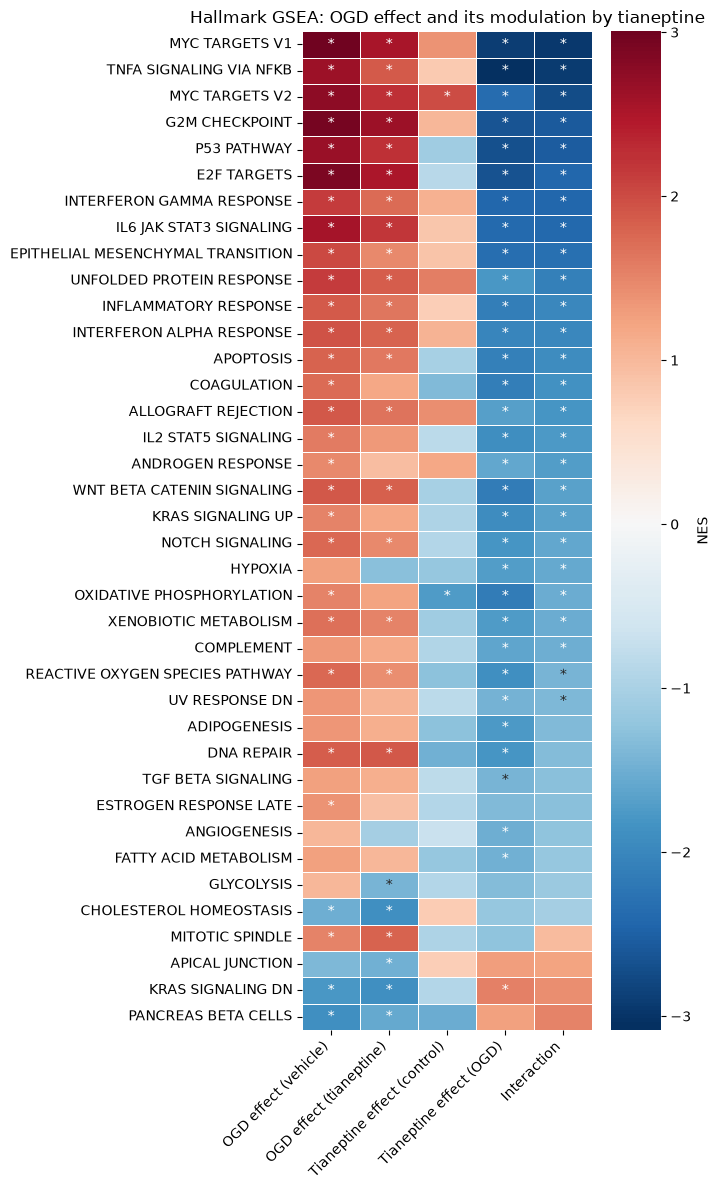

In [54]:
fig, ax = plt.subplots(figsize=(7, 12))
sns.heatmap(nes_plot, cmap="RdBu_r", center=0, annot=stars, fmt="", linewidths=0.5, cbar_kws={"label": "NES"}, ax=ax)
ax.set_title("Hallmark GSEA: OGD effect and its modulation by tianeptine")
ax.set_ylabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("../results/GSEA_hallmark_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

#### Interpretation

The heatmap summarises all five GSEA comparisons (38 Hallmark gene sets significant in at least one comparison; rows ordered by interaction NES; * FDR < 0.05):

1. **OGD effect (vehicle):** OGD strongly increases inflammatory, p53/apoptotic, stress-response and proliferative gene sets (red).
2. **OGD effect (tianeptine):** The same sets are still increased, with somewhat lower NES values.
3. **Tianeptine effect (control):** Almost no changes; only MYC targets V2 (up) and oxidative phosphorylation (down) are significant.
4. **Tianeptine effect (OGD):** In OGD-exposed cultures, tianeptine decreases nearly all OGD-induced gene sets (blue).
5. **Interaction:** The same pattern, confirming that the tianeptine effect is specific to OGD.

The bottom rows show the opposite pattern: gene sets decreased by OGD (KRAS signaling DN, pancreas beta cells; both containing neuronal and ion channel genes) tend to be restored by tianeptine under OGD.

**Overall:** Tianeptine has little effect on these gene sets in healthy cultures, but selectively attenuates the OGD-induced inflammatory, p53/apoptotic, oxidative stress and glial activation programmes. This is consistent with a context-dependent neuroprotective effect.

## 5. Summary

**Data:** Primary cortical cultures, 4 groups (CONTROL-VEH, CONTROL-TIA, OGD-VEH, OGD-TIA; n = 4 each). RNA collected 6 h after OGD. Differential expression from PyDESeq2 (notebook 02).

**ORA (g:Profiler, sections 2–3)**
- In vehicle, OGD changed 1832 genes. Upregulated genes were enriched in inflammation, p53/apoptosis, oxidative stress and cell cycle pathways; downregulated genes in neuronal receptor, calcium/cAMP and synaptic signaling.
- 14 of the 16 KEGG pathways reported in the original publication were reproduced. Analysing up- and downregulated genes separately clarified the direction of each pathway and recovered pathways lost in the combined analysis.
- In tianeptine-treated cultures, OGD changed fewer genes (292), and fewer pathways reached significance. Both pathways reported in the original publication for this comparison (neuroactive ligand-receptor interaction, TNF signaling) were reproduced.

**GSEA (MSigDB mouse Hallmark, section 4)**
- OGD induced the same inflammatory, p53/apoptotic, stress and proliferative programmes in both vehicle and tianeptine-treated cultures, showing that the smaller ORA results in tianeptine largely reflected lower power.
- Tianeptine had almost no effect on these programmes in control cultures (2 of 50 gene sets changed).
- In OGD-exposed cultures, tianeptine significantly attenuated 31 gene sets, and the interaction analysis identified 26 gene sets whose OGD induction was significantly weaker with tianeptine. The strongest were TNFα signaling via NF-κB, MYC targets, p53 pathway, G2M checkpoint, interferon γ response, IL6/JAK/STAT3 signaling and epithelial-mesenchymal transition.

**Conclusion:** Although no single gene showed a significant interaction, tianeptine selectively attenuates the OGD-induced inflammatory, p53/apoptotic, oxidative stress and glial activation programmes at the gene set level. This provides a molecular signature consistent with its neuroprotective effect.

**Limitations:** Small sample size (n = 4 per group); experimental week (batch; inferred from expression data and consistent with sample numbering) not included in the model; pre-ranked GSEA may give optimistic FDR values because it does not account for correlation between genes; the Hallmark collection contains no neuron-specific gene sets; transcript changes do not directly demonstrate functional effects.